In [15]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from pathlib import Path

In [16]:
GRAPHS = {
    "google": Path("bfs_res/web-Google"),
    "wikiTalk":   Path("bfs_res/wiki-Talk"),
    "wikiTopcats":  Path("bfs_res/wiki-topcats"),
}

In [45]:
def get_stat(df, region, category):
    s = df.loc[(df["REGION"] == region) & (df["CATEGORY"] == category), "TOTAL"]
    s = pd.to_numeric(s, errors="coerce")
    return s.iloc[0] if len(s) else np.nan

In [46]:
def median_stat(df, region_pat, category_pat):
    m = df["REGION"].str.fullmatch(region_pat) & df["CATEGORY"].str.fullmatch(category_pat)
    return pd.to_numeric(df.loc[m, "TOTAL"], errors="coerce").median()

In [20]:
rows = []
for graph, folder in GRAPHS.items():
    for path in sorted(folder.glob("n*_t*.csv")):
        m = re.fullmatch(r"n(\d+)_t(\d+)\.csv", path.name)
        if not m:
            continue
        n, t = int(m.group(1)), int(m.group(2))

        df = pd.read_csv(path, skipinitialspace=True)
        df["REGION"] = df["REGION"].astype(str).str.strip()
        df["CATEGORY"] = df["CATEGORY"].astype(str).str.strip()

        rows.append({
            "graph": graph,
            "hosts": n,
            "threads": t,
            # Timer_0 ... Timer_9 в регионе BFS: время алгоритма целиком (TimerTotal не попадает)
            "median_timer_ms": median_stat(df, r"BFS", r"Timer_\d+"),
            # BFS_0 ... BFS_9, категория Time: только вычислительные циклы
            "median_loop_ms": median_stat(df, r"BFS_\d+", r"Time"),
            # Gluon, Sync_BFS_N: время синхронизации между хостами
            "median_sync_ms": median_stat(df, r"Gluon",  r"Sync_BFS_\d+"),
            # Gluon, ReduceSendBytes_BFS_N: байты, отправленные за один прогон
            "median_reduce_send_bytes": median_stat(df, r"Gluon",  r"ReduceSendBytes_BFS_\d+"),
            # Одно значение на файл
            "replication_factor": get_stat(df, "Gluon", "ReplicationFactor"),
            "iter_num": median_stat(df, r"BFS",  r"NumIterations_\d+"),
            "work_items_num": median_stat(df, r"BFS",  r"NumWorkItems_\d+"),
        })

result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("bfs_stats.csv", index=False)
print(result.to_string(index=False))

      graph  hosts  threads  median_timer_ms  median_loop_ms  median_sync_ms  median_reduce_send_bytes  replication_factor  iter_num  work_items_num
     google      1        1             42.0            35.0             NaN                       NaN             1.00000      20.0       5371710.0
     google      1        2             23.5            17.0             NaN                       NaN             1.00000      19.5       5815432.5
     google      1        3             16.0            11.0             NaN                       NaN             1.00000      21.0       5400684.0
     google      1        4             17.5            12.0             NaN                       NaN             1.00000      19.0       5490843.0
     google      1        5             19.0            15.0             NaN                       NaN             1.00000      21.0       5537016.0
     google      1        6             21.0            15.0             NaN                       NaN    

In [ ]:
result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("bfs_stats.csv", index=False)
print(result.to_string(index=False))

result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("bfs_stats.csv", index=False)

df = pd.read_csv('bfs_stats.csv')

In [22]:
df

,graph,hosts,threads,median_timer_ms,median_loop_ms,median_sync_ms,median_reduce_send_bytes,replication_factor,iter_num,work_items_num
0,google,1,1,42.0,35.0,NaN,NaN,1.00000,20.0,5371710.0
1,google,1,2,23.5,17.0,NaN,NaN,1.00000,19.5,5815432.5
2,google,1,3,16.0,11.0,NaN,NaN,1.00000,21.0,5400684.0
3,google,1,4,17.5,12.0,NaN,NaN,1.00000,19.0,5490843.0
4,google,1,5,19.0,15.0,NaN,NaN,1.00000,21.0,5537016.0
5,google,1,6,21.0,15.0,NaN,NaN,1.00000,20.0,5842732.5
6,google,1,7,21.5,17.0,NaN,NaN,1.00000,21.0,6113066.0
7,google,1,8,86.5,76.5,NaN,NaN,1.00000,21.0,5228555.0
8,google,2,1,81.5,33.0,20.0,4884844.0,1.58001,36.0,9190083.0
9,google,2,2,90.5,41.0,19.0,4926640.0,1.58001,35.5,9175361.0


# Общие вычисления

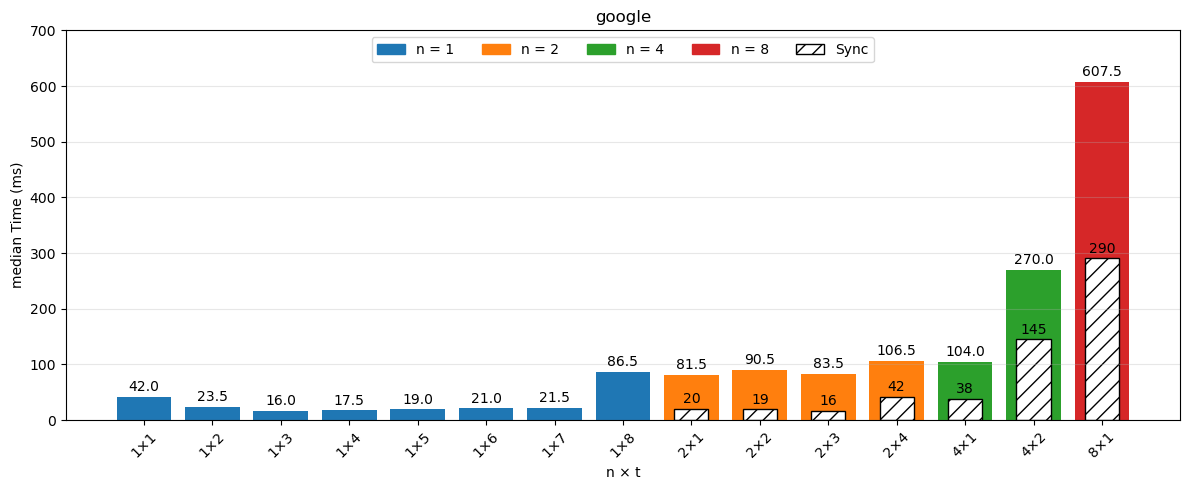

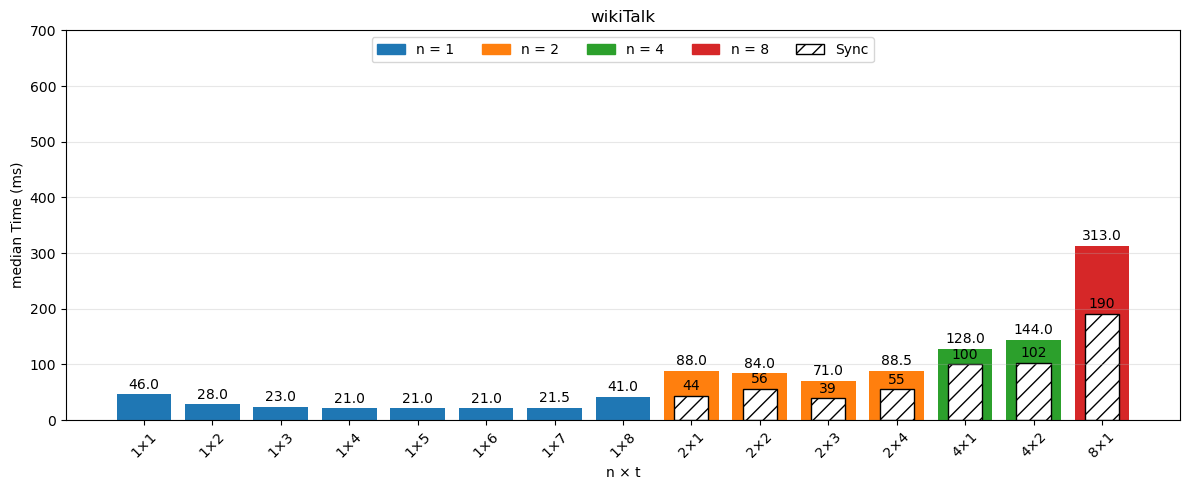

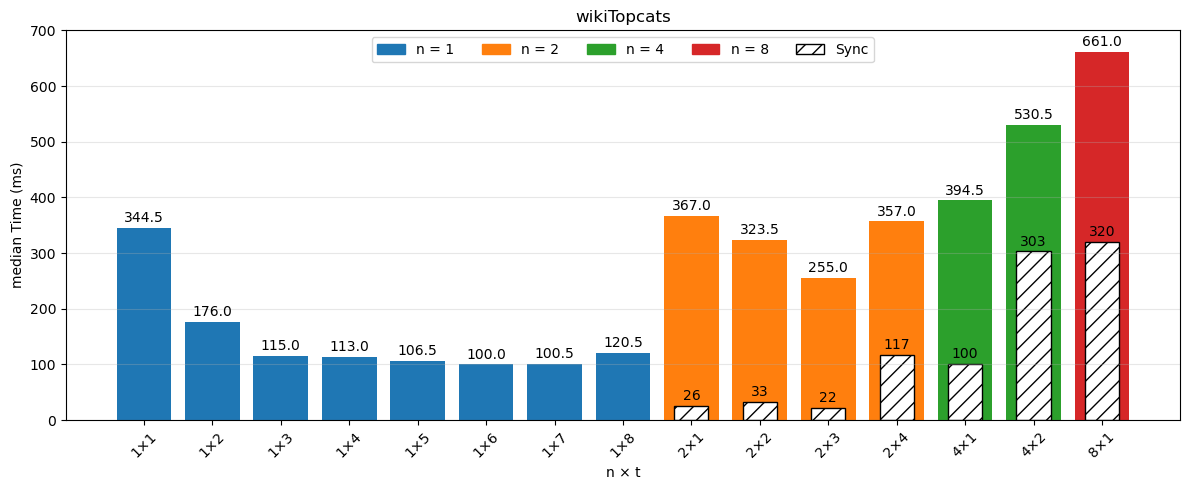

In [28]:
df = df.sort_values(["graph", "hosts", "threads"])
hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]
    timer = sub["median_timer_ms"].values
    sync = sub["median_sync_ms"].values            # для n = 1 здесь NaN: столбца не будет

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, timer, color=colors, width=0.8)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=10)

    # Узкий столбец внутри: Sync
    sbars = ax.bar(labels, sync, width=0.5, color="white", edgecolor="black",
                   hatch="//")
    ymax = np.nanmax(timer)
    ax.bar_label(sbars, labels=["" if np.isnan(v) else f"{v:.0f}" for v in sync],
                 label_type="edge", padding=2, fontsize=10,
                 bbox=dict(facecolor="none", edgecolor="none"))
    
    # ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("median Time (ms)")
    ax.set_ylim(0, 700)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)

    present = sorted(sub["hosts"].unique())
    handles = [Patch(color=color_of[n], label=f"n = {n}") for n in present]
    handles.append(Patch(facecolor="white", edgecolor="black", hatch="//", label="Sync"))
    ax.legend(handles=handles, loc="upper center", ncol=len(handles))

    fig.tight_layout()
    fig.savefig(f"time_with_sync_{g}.png", dpi=150)
    plt.show()

# "Чистые" вычисления

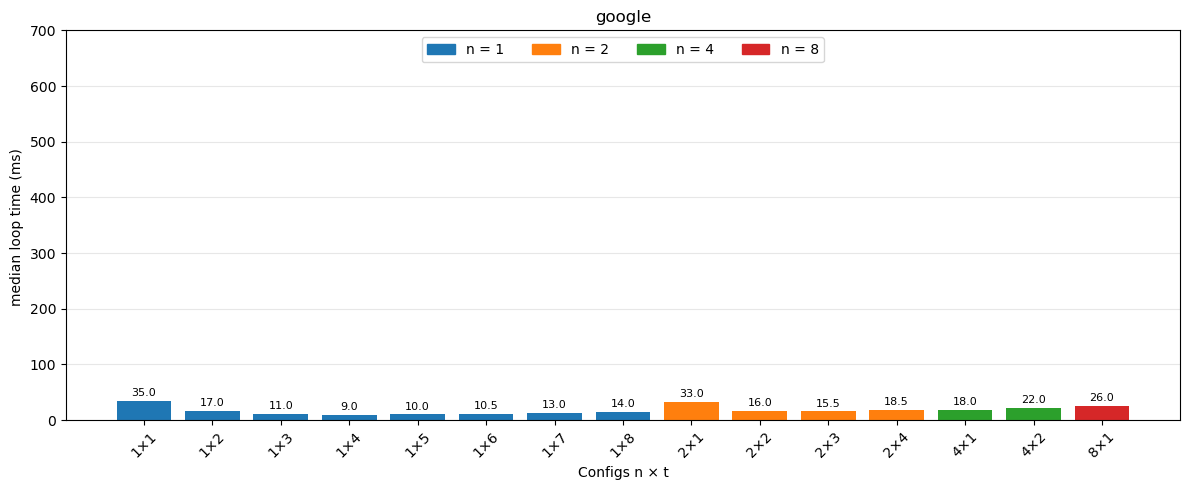

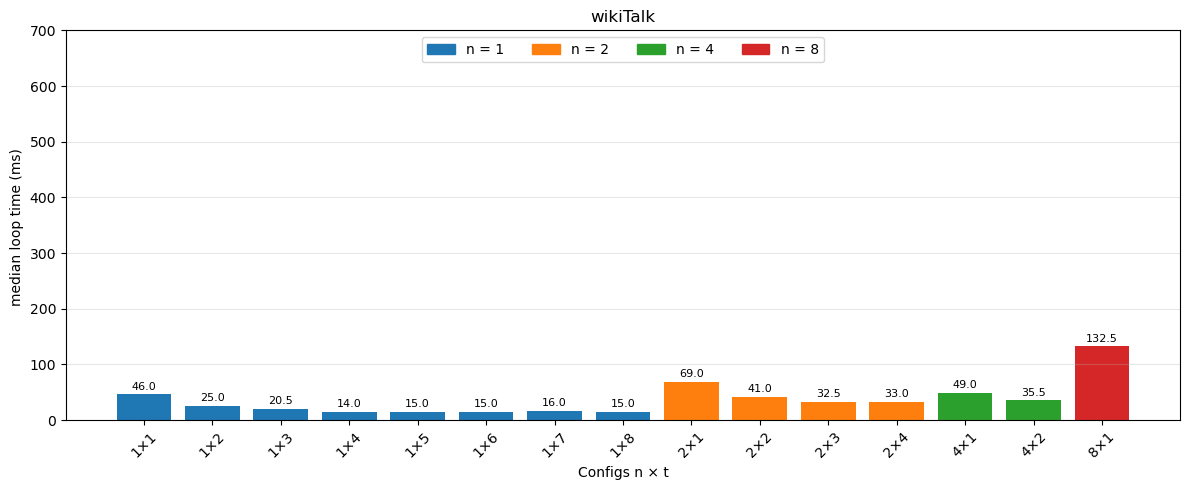

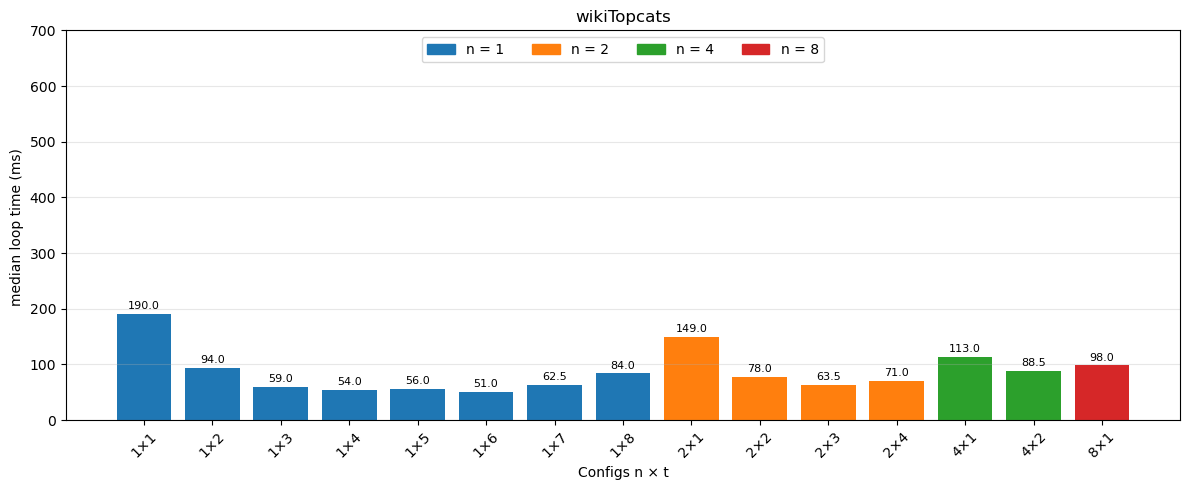

In [35]:
df = df.sort_values(["graph", "hosts", "threads"])

hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, sub["median_loop_ms"], color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)

    ax.set_title(g)
    ax.set_xlabel("Configs n × t")
    ax.set_ylabel("median loop time (ms) ")
    ax.set_ylim(0, 700)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)

    present = sorted(sub["hosts"].unique())
    ax.legend(handles=[Patch(color=color_of[n], label=f"n = {n}") for n in present],
              loc="upper center", ncol=len(present))

    fig.tight_layout()
    fig.savefig(f"avg_time_{g}.png", dpi=150)
    plt.show()

# Replication Factor

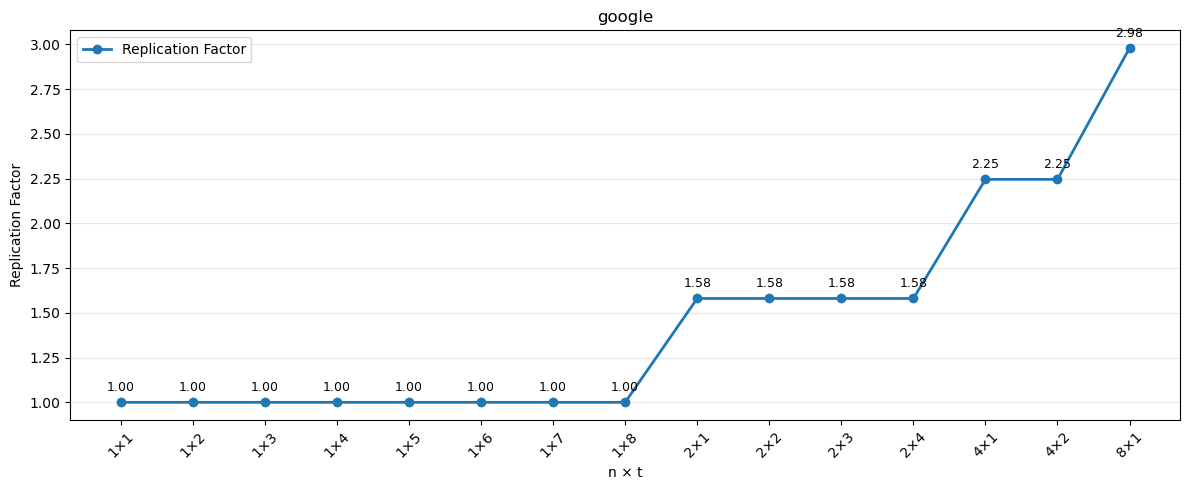

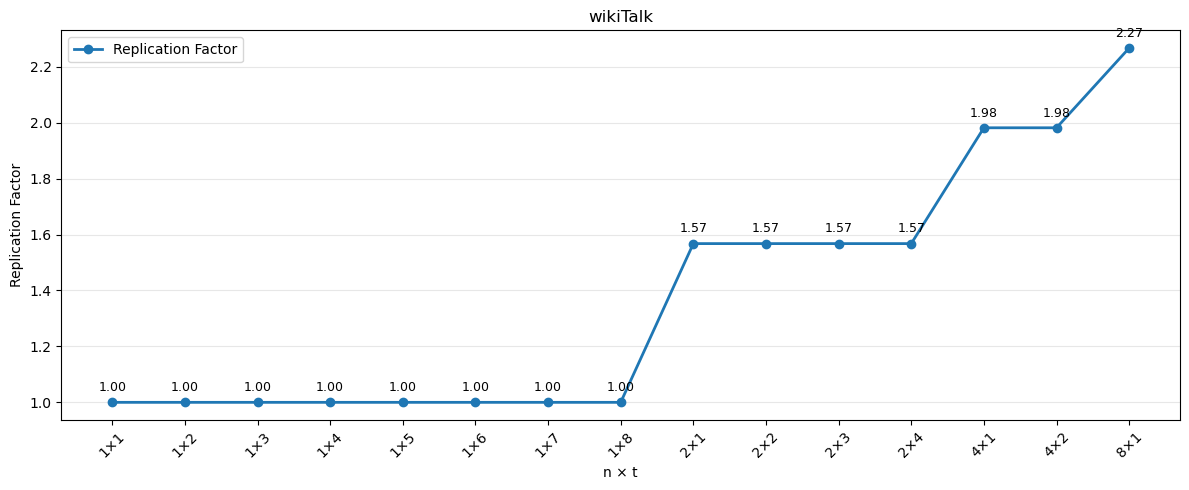

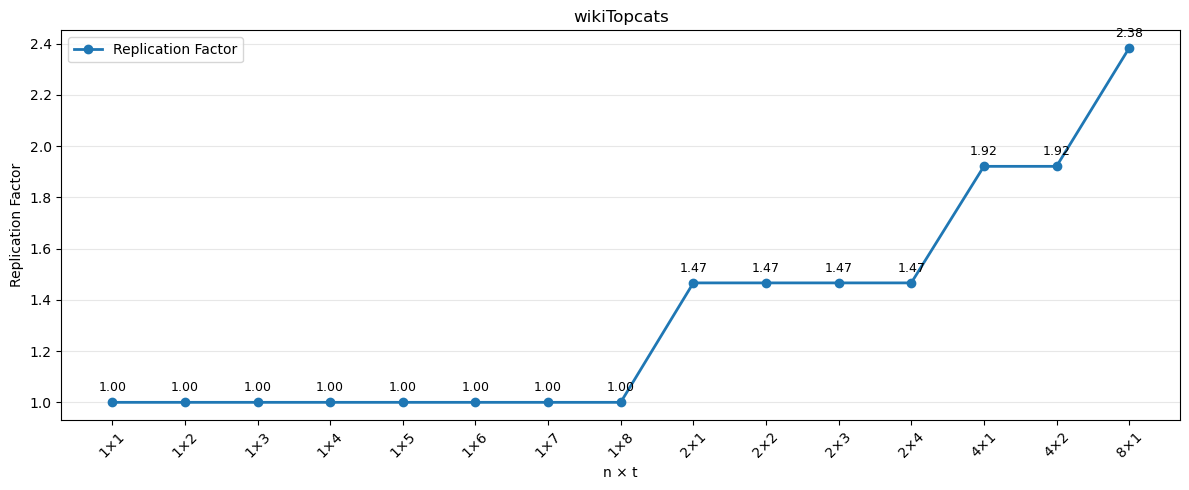

In [10]:
df = df.sort_values(["graph", "hosts", "threads"])

for g in df["graph"].unique():
    sub = df[df["graph"] == g].copy()

    # Конфигурация на оси X
    sub["config"] = (
        sub["hosts"].astype(str) + "×" +
        sub["threads"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(12, 5))

    # Line 1 — nodes
    ax.plot(
        sub["config"],
        sub["replication_factor"],
        marker="o",
        linewidth=2,
        label="Replication Factor"
    )

    # Подписи значений nodes
    for i, value in enumerate(sub["replication_factor"]):
        ax.annotate(
            f"{value:.2f}",
            (i, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("Replication Factor")

    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(f"replication_factor_{g}.png", dpi=150)
    plt.show()

# Объем передаваемых данных

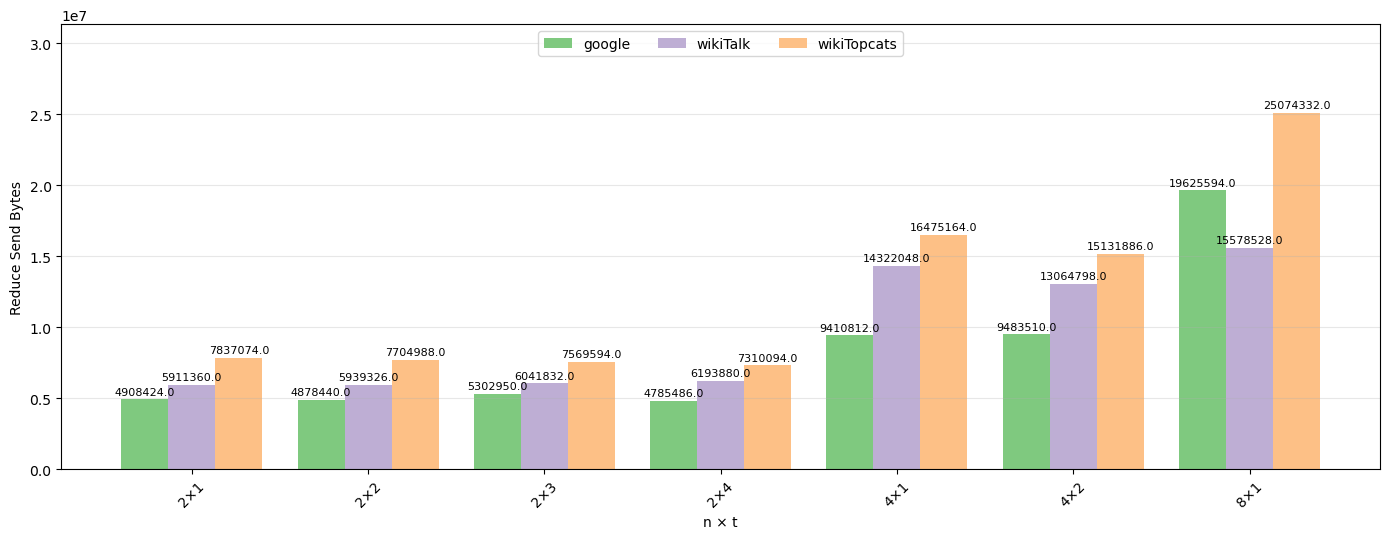

In [30]:
pivot = (df.pivot_table(index=["hosts", "threads"], columns="graph",
                        values="median_reduce_send_bytes"))
pivot = pivot.dropna(how="all")          # конфигурации без данных (например, n=1) не рисуем

configs = [f"{n}×{t}" for n, t in pivot.index]
graphs = list(pivot.columns)
x = np.arange(len(configs))
w = 0.8 / len(graphs)                    # ширина одного столбца
cmap = plt.get_cmap("Accent")

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, g in enumerate(graphs):
    vals = pivot[g].values
    bars = ax.bar(x + (i - (len(graphs) - 1) / 2) * w, vals, w, label=g, color=cmap(i))
    ax.bar_label(bars, labels=[f"{v:.1f}" if not np.isnan(v) else "" for v in vals],
                 padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=45)
ax.set_xlabel("n × t")
ax.set_ylabel("Reduce Send Bytes")
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.25)
ax.legend(loc="upper center", ncol=len(graphs))

fig.tight_layout()
fig.savefig("reduce_send_bytes.png", dpi=150)
plt.show()

# Количество итераций

In [72]:
df = pd.read_csv('bfs_stats.csv')

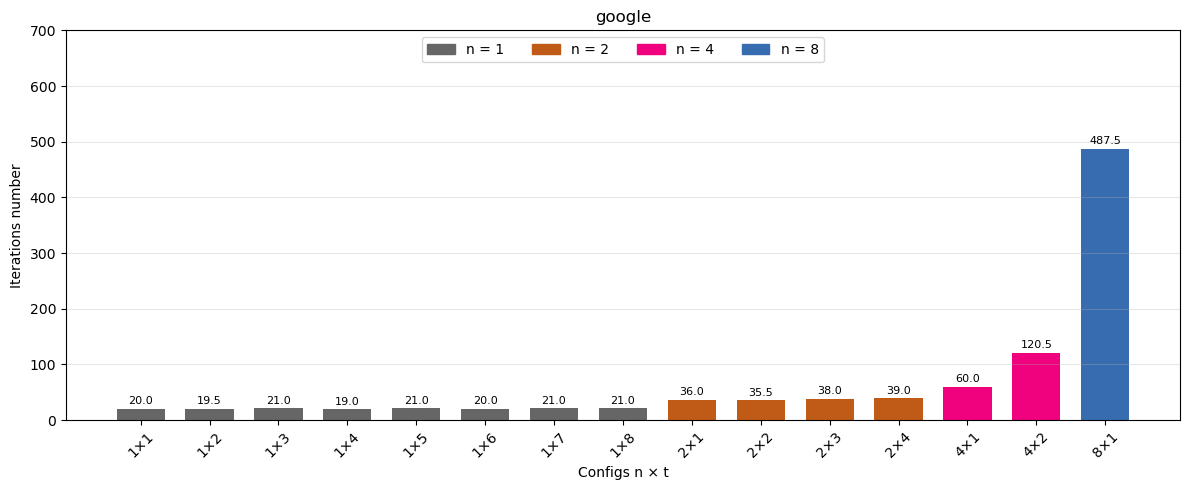

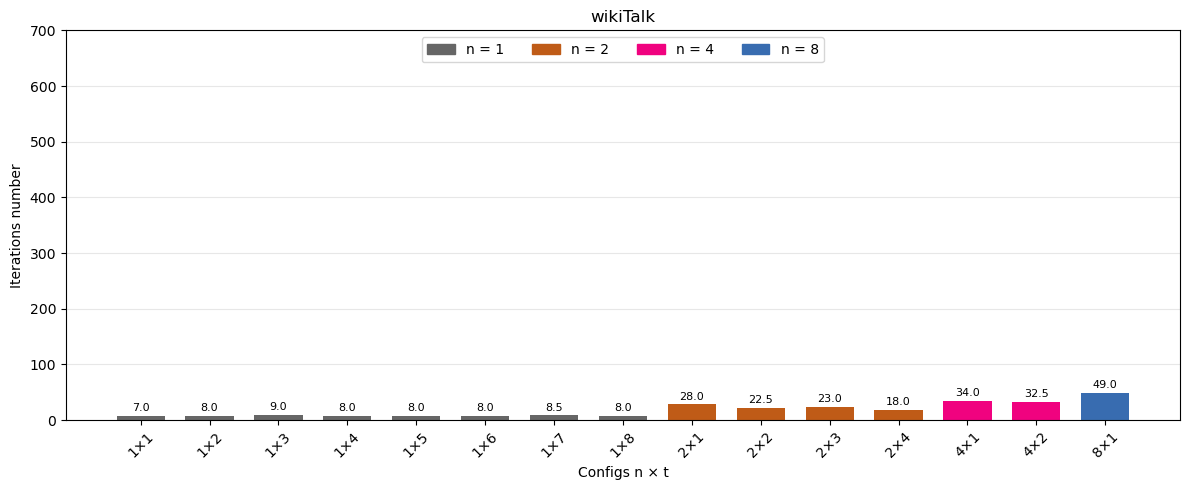

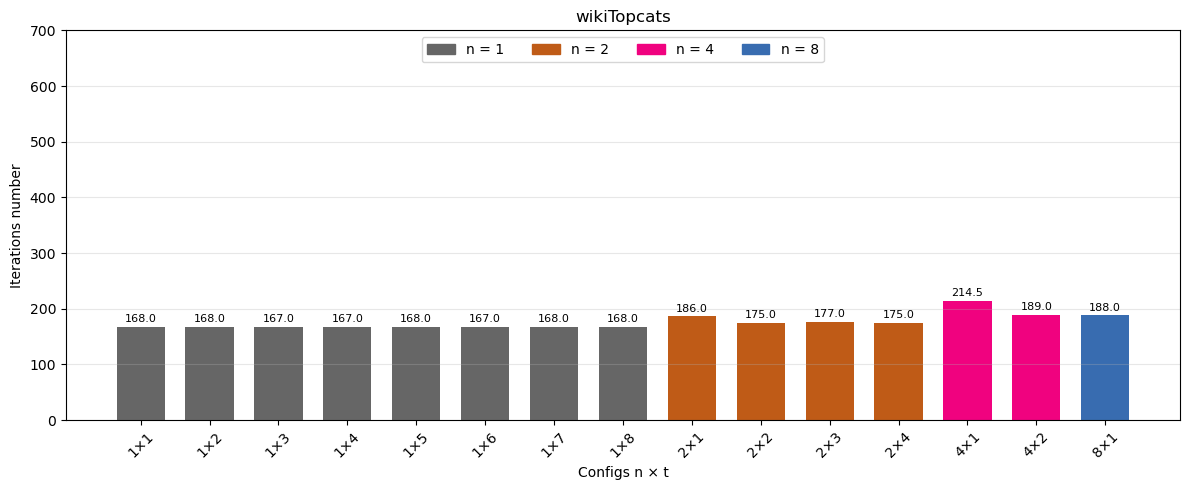

In [83]:
df = df.sort_values(["graph", "hosts", "threads"])

hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("Accent_r")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, sub["iter_num"], color=colors, width=0.7)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("Configs n × t")
    ax.set_ylabel("Iterations number")
    ax.set_ylim(0, 700)  # ось Y от 0 до 700
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)                                       # место под легенду и подписи сверху

    # Легенда по центру сверху, в одну строку
    present = sorted(sub["hosts"].unique())
    ax.legend(handles=[Patch(color=color_of[n], label=f"n = {n}") for n in present],
              loc="upper center", ncol=len(present))

    fig.tight_layout()
    fig.savefig(f"iters_{g}.png", dpi=150)
    plt.show()

# Общие вычисления с новым таймером

In [44]:
GRAPHS = {
    "google": Path("new_bfs_res/web-Google"),
    "wikiTalk":   Path("new_bfs_res/wiki-Talk"),
    "wikiTopcats":  Path("new_bfs_res/wiki-topcats"),
}

In [47]:
rows = []
for graph, folder in GRAPHS.items():
    for path in sorted(folder.glob("n*_t*.csv")):
        m = re.fullmatch(r"n(\d+)_t(\d+)\.csv", path.name)
        if not m:
            continue
        n, t = int(m.group(1)), int(m.group(2))

        df = pd.read_csv(path, skipinitialspace=True)
        df["REGION"] = df["REGION"].astype(str).str.strip()
        df["CATEGORY"] = df["CATEGORY"].astype(str).str.strip()

        rows.append({
            "graph": graph,
            "hosts": n,
            "threads": t,
            # Timer_0 ... Timer_9 в регионе BFS: время алгоритма целиком (TimerTotal не попадает)
            "median_timer_ms": median_stat(df, r"BFS", r"Timer_\d+"),
            # BFS_0 ... BFS_9, категория Time: только вычислительные циклы
            "median_loop_ms": median_stat(df, r"BFS_\d+", r"Time"),
            # Gluon, Sync_BFS_N: время синхронизации между хостами
            "median_sync_ms": median_stat(df, r"Gluon",  r"Sync_BFS_\d+"),
            # Gluon, ReduceSendBytes_BFS_N: байты, отправленные за один прогон
            "median_reduce_send_bytes": median_stat(df, r"Gluon",  r"ReduceSendBytes_BFS_\d+"),
            # Одно значение на файл
            "replication_factor": get_stat(df, "Gluon", "ReplicationFactor"),
            "iter_num": median_stat(df, r"BFS",  r"NumIterations_\d+"),
            "work_items_num": median_stat(df, r"BFS",  r"NumWorkItems_\d+"),
        })

result = (pd.DataFrame(rows)
            .sort_values(["graph", "hosts", "threads"])
            .reset_index(drop=True))
result.to_csv("new_bfs_stats.csv", index=False)

df = pd.read_csv('new_bfs_stats.csv')
df

,graph,hosts,threads,median_timer_ms,median_loop_ms,median_sync_ms,median_reduce_send_bytes,replication_factor,iter_num,work_items_num
0,google,1,1,45.6300,45.5765,0.0110,NaN,1.00000,20.0,5371710.0
1,google,1,2,26.3580,26.3070,0.0120,NaN,1.00000,20.0,5818526.0
2,google,1,3,17.8175,17.7635,0.0075,NaN,1.00000,21.0,5356848.5
3,google,1,4,18.3655,18.2870,0.0045,NaN,1.00000,20.0,5423217.0
4,google,1,5,20.8160,20.7470,0.0055,NaN,1.00000,21.0,5549096.0
5,google,1,6,21.7125,21.6615,0.0055,NaN,1.00000,20.0,5814675.0
6,google,1,7,24.4690,24.4190,0.0060,NaN,1.00000,21.0,5888219.5
7,google,1,8,66.1535,66.0780,0.0055,NaN,1.00000,20.0,5196856.0
8,google,2,1,84.1810,46.0785,38.8365,4876478.0,1.58001,36.0,9184035.5
9,google,2,2,84.0660,44.5670,42.7085,4614186.0,1.58001,37.5,8470326.5


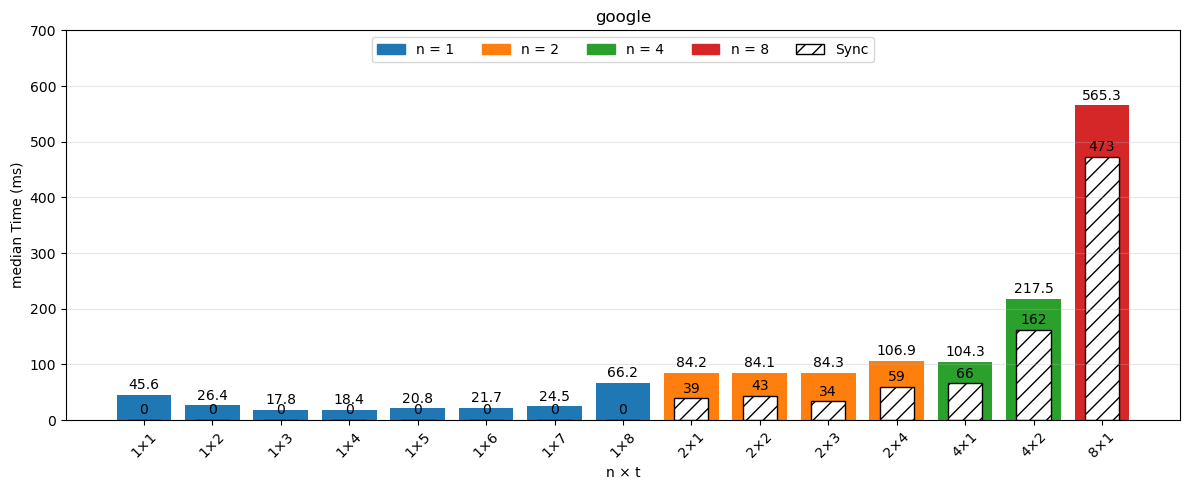

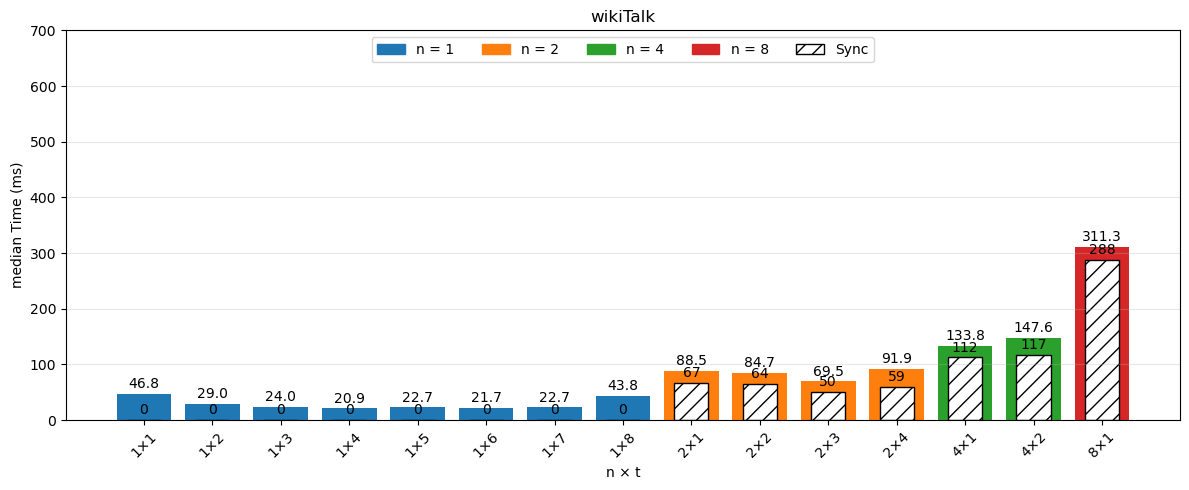

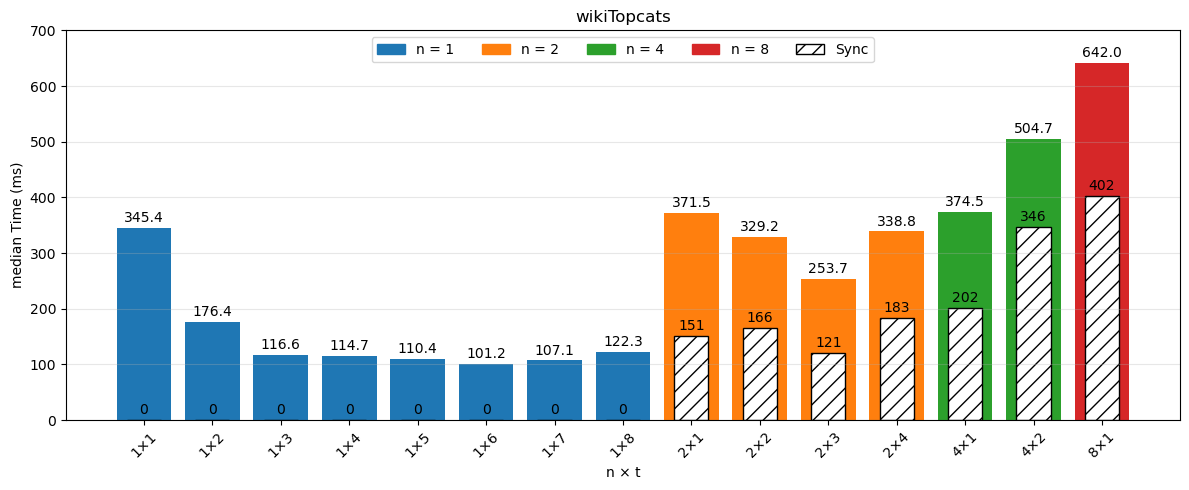

In [63]:
df = df.sort_values(["graph", "hosts", "threads"])
hosts_values = sorted(df["hosts"].unique())
cmap = plt.get_cmap("tab10")
color_of = {n: cmap(i) for i, n in enumerate(hosts_values)}

for g in df["graph"].unique():
    sub = df[df["graph"] == g]
    labels = [f"{n}×{t}" for n, t in zip(sub["hosts"], sub["threads"])]
    colors = [color_of[n] for n in sub["hosts"]]
    timer = sub["median_timer_ms"].values
    sync = sub["median_sync_ms"].values            # для n = 1 здесь NaN: столбца не будет

    fig, ax = plt.subplots(figsize=(12, 5))
    bars = ax.bar(labels, timer, color=colors, width=0.8)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=10)

    # Узкий столбец внутри: Sync
    sbars = ax.bar(labels, sync, width=0.5, color="white", edgecolor="black",
                   hatch="//")
    ymax = np.nanmax(timer)
    ax.bar_label(sbars, labels=["" if np.isnan(v) else f"{v:.0f}" for v in sync],
                 label_type="edge", padding=2, fontsize=10,
                 bbox=dict(facecolor="none", edgecolor="none"))
    
    # ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)   # значение над столбцом

    ax.set_title(g)
    ax.set_xlabel("n × t")
    ax.set_ylabel("median Time (ms)")
    ax.set_ylim(0, 700)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.2)

    present = sorted(sub["hosts"].unique())
    handles = [Patch(color=color_of[n], label=f"n = {n}") for n in present]
    handles.append(Patch(facecolor="white", edgecolor="black", hatch="//", label="Sync"))
    ax.legend(handles=handles, loc="upper center", ncol=len(handles))

    fig.tight_layout()
    fig.savefig(f"time_with_sync_{g}.png", dpi=150)
    plt.show()